# Scalable Recommender System: From First Principles to Production
**Course:** Applied Machine Learning at Scale (AIMS)  
**Dataset:** MovieLens (ml-32m)

---

## Table of Contents
1. **Practical 1:** Data Understanding & Scale-Free Degree Distributions
2. **Practical 2:** Baseline Model (User & Item Biases via ALS)
3. **Practical 3:** Latent Factor Model & 2D Trait Embeddings
4. **Practical 4:** Numba CSR, Optuna Tuning, Polarization & Dummy Users


If running on colab, it's best to run Practical 4 in a new colab session in other to avoid out of memory errors


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [optuna]


In [3]:
import math
from typing import Counter
import random
import gc
import csv
import pickle
import os

import numpy as np
import matplotlib.pyplot as plt

import optuna
import numba
from numba import njit, prange


In [4]:
figures_dir = "/content/drive/MyDrive/AIMS Courses/Block 02 - Applied Machine Learning at Scale/Practicals/figures"
os.makedirs(figures_dir, exist_ok=True)

## Practical 1: Data Understanding & Scale-Free Degree Distributions

**Task**
* Download the MovieLens 32M data set and understand its README
* Write a data structure that indexes the data (a) by user and (b) by movie
* Plot rating distributions of data
* Are there power laws in the data? Is it scale-free? (Note that each user rated at least 20 movies. Truncation will skew the power law that you’d expect…)


### Load the MovieLense Dataset

In [5]:
data_path = "/content/drive/MyDrive/AIMS Courses/Block 02 - Applied Machine Learning at Scale/Practicals/dataset/ml-32m/ratings.csv"

csv_data = np.loadtxt(data_path, delimiter=',', skiprows=1)

In [6]:
# Sort in ascecding order by timestamp
data = csv_data[csv_data[:,3].argsort()]
data[:5]

array([[2.50620000e+04, 1.17600000e+03, 4.00000000e+00, 7.89652004e+08],
       [3.09170000e+04, 1.07900000e+03, 3.00000000e+00, 7.89652009e+08],
       [3.09170000e+04, 2.10000000e+01, 3.00000000e+00, 7.89652009e+08],
       [3.09170000e+04, 4.70000000e+01, 5.00000000e+00, 7.89652009e+08],
       [4.37200000e+04, 1.80000000e+01, 4.00000000e+00, 8.22873600e+08]])

### Build Data Structure that Indexes the data by User and by Movie

`user_to_index:dict[int, float] = {}`   # A dictionary that maps "userId" to the index of the user in the dataset

`index_to_user:list[tuple[int, float]] = []`  # A list containing the "userId" of all users, where by each userId is placed at the index set within user_to_index

`movie_to_index:dict[int, float] = {}`  # A dictionary that maps "movieId" to the index of the movie in the dataset

`index_to_movie:list[int] = []`   # A list containing the "movieId" of all movies, where by each movieId is placed at the index set within movie_to_index

`data_by_user:list[list[tuple[int, float]]] = []`   # A list where every index corresponse to a user, where each sub-list represent a tuple of movieId and ratings given by a user for a given movie.

`data_by_movie:list[list[tuple[int, float]]] = []`  # A list where every index corresponse to a movie, where each sub-list represents a tuple of userId and ratings given to the movie by the corresponding user.

In [7]:
def build_data_structure(data):
  # Six Data Structures

  user_to_index = {}        # {userId: idx}
  index_to_user = []        # [userId_1, userId_2]

  movie_to_index = {}       # {movieId: idx}
  index_to_movie = []       # A [movieId_1, movieId_2]

  data_by_user = []         # [[(movieId_1: rating_x), (movieId_2: rating_y)], [(movieId_2: rating_y), (movieId_8: rating_x)]]
  data_by_movie = []        # [[(userId_2: rating_x), (movieId_5: rating_y)], [(movieId_3: rating_y), (movieId_5: rating_x)]]


  for i in range(len(data)):  # Loop through every rating in the dataset

    # Add user entry into user_to_index and index_to_user dictionary, if it's not yet added
    if data[i][0] not in user_to_index:
      user_to_index[data[i][0]] = len(index_to_user)
      index_to_user.append(data[i][0])

    # Add movie entry into movie_to_index and index_to_movie dictionary, if it's not yet added
    if data[i][1] not in movie_to_index:
      movie_to_index[data[i][1]] = len(index_to_movie)
      index_to_movie.append(data[i][1])

    # Add movie rating to the corresponding user's index in data_by_user
    new_data_by_user_entry = (movie_to_index[data[i][1]], data[i][2])
    if len(data_by_user) < user_to_index[data[i][0]] + 1:   # Check if user's index position doesn't exists in data_by_user
      data_by_user.append([new_data_by_user_entry])
    else:
      data_by_user[user_to_index[data[i][0]]].append(new_data_by_user_entry)

    # Add user's rating to the corresponding movie's index in data_by_movie
    new_data_by_movie_entry = (user_to_index[data[i][0]], data[i][2])
    if len(data_by_movie) < movie_to_index[data[i][1]] + 1:
      data_by_movie.append([new_data_by_movie_entry])
    else:
      data_by_movie[movie_to_index[data[i][1]]].append(new_data_by_movie_entry)

  return user_to_index, index_to_user, movie_to_index, index_to_movie, data_by_user, data_by_movie


In [8]:
(user_to_index,
 index_to_user,
 movie_to_index,
 index_to_movie,
 data_by_user,
 data_by_movie) = build_data_structure(data=data)


# print("User_to_index: \n", list(user_to_index.items())[:5])
# print("\nIndex_to_user: \n", index_to_user[:5])

# print("\n\nmovies_to_index: \n", list(movie_to_index.items())[:5])
# print("\nindex_to_movie: \n", index_to_movie[:5])

# print("\n\ndata_by_user: \n", data_by_user[:2])

# print("\ndata_by_movie: \n", data_by_movie[:2])

### Plot Rating Distribution

In [9]:
ratings_counter = Counter(csv_data[:, 2])
ratings_keys = list(ratings_counter.keys())
ratings_count = list(ratings_counter.values())


print("Rating_counter: ", ratings_counter)
print("keys: ", ratings_keys)
print("values: ", ratings_count)

Rating_counter:  Counter({np.float64(4.0): 8367654, np.float64(3.0): 6054990, np.float64(5.0): 4596577, np.float64(3.5): 4290105, np.float64(4.5): 2974000, np.float64(2.0): 2028622, np.float64(2.5): 1685386, np.float64(1.0): 946675, np.float64(1.5): 531063, np.float64(0.5): 525132})
keys:  [np.float64(4.0), np.float64(1.0), np.float64(2.0), np.float64(5.0), np.float64(3.0), np.float64(3.5), np.float64(0.5), np.float64(4.5), np.float64(2.5), np.float64(1.5)]
values:  [8367654, 946675, 2028622, 4596577, 6054990, 4290105, 525132, 2974000, 1685386, 531063]


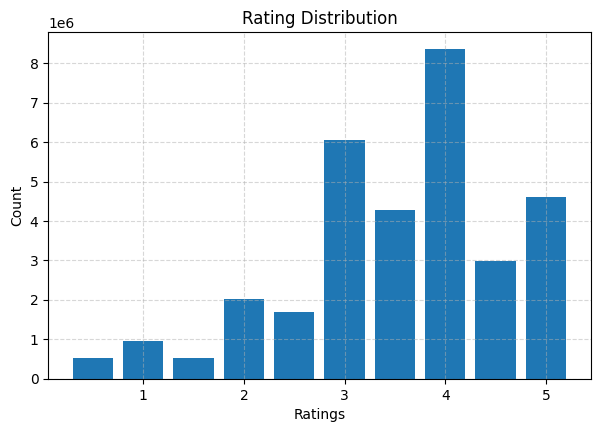

In [10]:
plt.figure(figsize=(7, 4.5))
plt.bar(x=ratings_keys, height=ratings_count, width=0.4)
plt.ylabel("Count")
plt.xlabel("Ratings")
plt.title("Rating Distribution")
plt.grid(True, linestyle="--", alpha=0.5)

plt.savefig(f"{figures_dir}/prac1_rating_distribution.pdf", format="pdf", bbox_inches="tight")
plt.show()


In [11]:
degree_of_movies_rated_per_users = [len(user) for user in data_by_user]
degree_of_users_who_rated_each_movie = [len(movie) for movie in data_by_movie]

frequencies_of_degree_of_movies_rated_per_users = Counter(degree_of_movies_rated_per_users)
frequencies_of_degree_of_users_who_rated_each_movie = Counter(degree_of_users_who_rated_each_movie)


# print("frequencies_of_degree_of_movies_rated_per_users: \n", frequencies_of_degree_of_movies_rated_per_users)
# print("\nfrequencies_of_degree_of_users_who_rated_each_movie: \n", frequencies_of_degree_of_users_who_rated_each_movie)

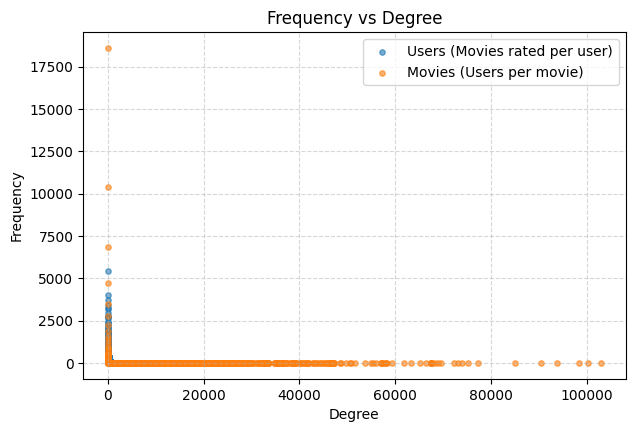

In [12]:
plt.figure(figsize=(7, 4.5))
plt.scatter(
    x=list(frequencies_of_degree_of_movies_rated_per_users.keys()),
    y=list(frequencies_of_degree_of_movies_rated_per_users.values()),
    label='Users (Movies rated per user)', alpha=0.6, s=15
)
plt.scatter(
    x=list(frequencies_of_degree_of_users_who_rated_each_movie.keys()),
    y=list(frequencies_of_degree_of_users_who_rated_each_movie.values()),
    label='Movies (Users per movie)', alpha=0.6, s=15
)

plt.ylabel("Frequency")
plt.xlabel("Degree")
plt.title("Frequency vs Degree")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()

plt.savefig(f"{figures_dir}/prac1_frequency_vs_degree.pdf", format="pdf", bbox_inches="tight")
plt.show()

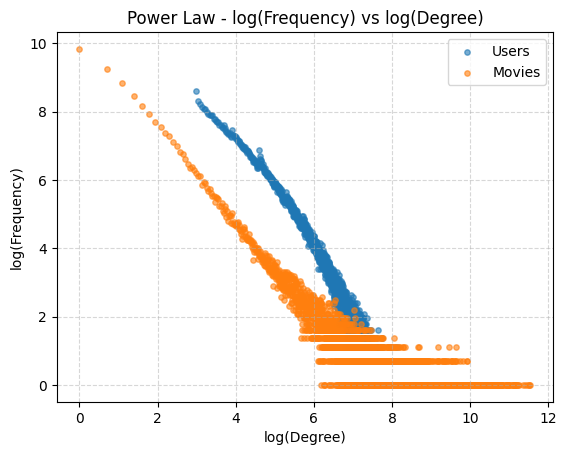

In [13]:
plt.scatter(
    x=[math.log(key) for key in frequencies_of_degree_of_movies_rated_per_users.keys()],
    y=[math.log(value) for value in frequencies_of_degree_of_movies_rated_per_users.values()],
    label="Users", alpha=0.6, s=15
)
plt.scatter(
    x=[math.log(key) for key in frequencies_of_degree_of_users_who_rated_each_movie.keys()],
    y=[math.log(value) for value in frequencies_of_degree_of_users_who_rated_each_movie.values()],
    label="Movies", alpha=0.6, s=15
)

plt.ylabel("log(Frequency)")
plt.xlabel("log(Degree)")
plt.title("Power Law - log(Frequency) vs log(Degree)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()

plt.savefig(f"{figures_dir}/prac1_power_law_log_log.pdf", format="pdf", bbox_inches="tight")
plt.show()

The Distribution follows the power law as seen from the curve above.

In [14]:
# cleanup of heavy array
del user_to_index
del index_to_user
del movie_to_index
del index_to_movie
del data_by_user
del data_by_movie
del degree_of_movies_rated_per_users
del degree_of_users_who_rated_each_movie
del frequencies_of_degree_of_movies_rated_per_users
del frequencies_of_degree_of_users_who_rated_each_movie
del ratings_counter, ratings_keys, ratings_count

gc.collect()

7464

## Practical 2: Baseline Model (User & Item Biases via ALS)

**Task**

* Download a smaller MovieLens dataset to develop and debug with, and again index it
* Split the small data set into a training and a test set.
* Build a model that finds maximum likelihood estimate for user + item biases with alternating least squares
* Plot the loss function (negative log likelihood) over training iterations, using `data_by_user_train`. It should go down monotonically!
Note that if you plotted the loss function using data_by_movie_train, the answers would be the same
* Plot the root mean squared error over training iterations, using data_by_user_train. What does it converge to?
* Plot the root mean squared error for data_by_user_test after each training iteration. What does it converge to? Does it follow the training error?



In [15]:
# Select the first 1 million rows of the dataset to build the pipeline, instead of using the entire dataset of 32 million records.
# This helps in reducing compute time required in testing the pipeline

data = csv_data[0:1_000_000]
data[:5]

array([[1.00000000e+00, 1.70000000e+01, 4.00000000e+00, 9.44249077e+08],
       [1.00000000e+00, 2.50000000e+01, 1.00000000e+00, 9.44250228e+08],
       [1.00000000e+00, 2.90000000e+01, 2.00000000e+00, 9.43230976e+08],
       [1.00000000e+00, 3.00000000e+01, 5.00000000e+00, 9.44249077e+08],
       [1.00000000e+00, 3.20000000e+01, 5.00000000e+00, 9.43228858e+08]])

In [16]:
# Build Data Structure that Indexes the data by User and by Movie
(user_to_index,
 index_to_user,
 movie_to_index,
 index_to_movie,
 data_by_user,
 data_by_movie) = build_data_structure(data=data)

In [17]:
# print("User_to_index: \n", user_to_index)
# print("\nIndex_to_user: \n", index_to_user[:5])

# print("\n\nmovies_to_index: \n", movie_to_index)
# print("\nindex_to_movie: \n", index_to_movie[:5])

# print("\n\ndata_by_user: \n", data_by_user[:2])

# print("\ndata_by_movie: \n", data_by_movie[:2])

### Data Spliting

Split data_by_user and data_by_movie into train and test using a random function.

In [18]:
def train_test_split(data_by_user, data_by_movie, test_size:float = 0.1):
  num_users = len(data_by_user)
  num_movies = len(data_by_movie)

  # initialise train and test sets for data by user and movie
  data_by_user_train = [[] for _ in range(num_users)]
  data_by_user_test  = [[] for _ in range(num_users)]

  data_by_movie_train = [[] for _ in range(num_movies)]
  data_by_movie_test  = [[] for _ in range(num_movies)]


  for user_idx, user_data in enumerate(data_by_user):
    for movie_rating in user_data:

      movie_idx, rating = movie_rating
      user_rating = [user_idx, rating]

      random_num = random.random()

      # Store Data in Test
      if random_num <= test_size:
        data_by_user_test[user_idx].append(movie_rating)
        data_by_movie_test[movie_idx].append(user_rating)

      else: # Store in Train
        data_by_user_train[user_idx].append(movie_rating)
        data_by_movie_train[movie_idx].append(user_rating)

  return data_by_user_train, data_by_user_test, data_by_movie_train, data_by_movie_test


In [20]:
(data_by_user_train,
 data_by_user_test,
 data_by_movie_train,
 data_by_movie_test) = train_test_split(data_by_user, data_by_movie, test_size = 0.1)


# print("User Data: ", data_by_user[:2])
# print("User Train: ", data_by_user_train[:2])
# print("User Test: ", data_by_user_test[:2])

# print("\n--------------------------------\n")

# print("Movie Data: ", data_by_movie[:2])
# print("Movie Train: ", data_by_movie_train[:2])
# print("Movie Test: ", data_by_movie_test[:2])

### Training

In [21]:
def calculate_loss(data_by_user, users_biases, movies_biases, h_lambda: float, h_gamma: float):
  squared_error_sum = 0.0

  for user_idx, user_data in enumerate(data_by_user):
    for movie_rating in user_data:
      if not movie_rating:
        continue
      movie_idx, rating = movie_rating
      error = rating - ( users_biases[user_idx] + movies_biases[movie_idx])
      squared_error_sum += error ** 2

  # L2 priors on biases
  regularizer_users = sum(bias ** 2 for bias in users_biases)
  regularizer_movies = sum(bias ** 2 for bias in movies_biases)

  negative_log_likelihood = (0.5 * h_lambda * squared_error_sum) + (0.5 * h_gamma * (regularizer_users + regularizer_movies))
  return negative_log_likelihood


def update_biases(data_by_user, data_by_movie, users_biases, movies_biases, h_lambda: float, h_gamma: float):
  updated_users_biases = users_biases.copy()
  updated_movies_biases = movies_biases.copy()

  # Update user biases
  for user_idx, user_data in enumerate(data_by_user):
    error_sum = 0.0
    number_of_users = 0
    for movie_rating in user_data:
      if not movie_rating:
        continue
      movie_idx, rating = movie_rating
      error_sum += rating - movies_biases[movie_idx]
      number_of_users += 1

    updated_users_biases[user_idx] = (h_lambda * error_sum) / ((h_lambda * number_of_users) + h_gamma)

  # Update movie bias
  for movie_idx, movie_data in enumerate(data_by_movie):
    error_sum = 0.0
    number_of_movies = 0
    for user_rating in movie_data:
      if not user_rating:
        continue
      user_idx, rating = user_rating
      error_sum += rating - updated_users_biases[user_idx]
      number_of_movies +=1

    updated_movies_biases[movie_idx] = (h_lambda * error_sum) / ((h_lambda * number_of_movies) + h_gamma)

  return updated_users_biases, updated_movies_biases


def calculate_root_mean_squared_error(data_by_user, users_biases, movies_biases):
  squared_error_sum = 0.0
  count = 0

  for user_idx, user_data in enumerate(data_by_user):
    for movie_rating in user_data:
      if not movie_rating:
        continue
      movie_idx, rating = movie_rating
      squared_error_sum += (rating - (users_biases[user_idx] + movies_biases[movie_idx])) ** 2
      count += 1

  return (squared_error_sum / count) ** 0.5 if count > 0 else 0.0


def train(data_by_user_train, data_by_movie_train, data_by_user_test,
          h_lambda: float, h_gamma: float, n_epochs: int):
  # Initialize biases
  num_users = len(data_by_user)
  num_movies = len(data_by_movie)
  users_biases = np.zeros(num_users)
  movies_biases = np.zeros(num_movies)

  train_losses = []
  train_rmses = []
  test_rmses = []

  for epoch in range(n_epochs):
    # ALS update
    users_biases, movies_biases = update_biases(
        data_by_user_train, data_by_movie_train,users_biases,
        movies_biases, h_lambda, h_gamma
        )

    loss = calculate_loss(data_by_user_train, users_biases, movies_biases, h_lambda, h_gamma)
    train_rmse = calculate_root_mean_squared_error(data_by_user_train, users_biases, movies_biases)
    test_rmse = calculate_root_mean_squared_error(data_by_user_test, users_biases, movies_biases)

    train_losses.append(loss)
    train_rmses.append(train_rmse)
    test_rmses.append(test_rmse)

    print(f"epoch {epoch + 1}/{n_epochs}, loss: {loss}, train rmse: {train_rmse}, test rmse: {test_rmse}")

  return users_biases, movies_biases, train_losses, train_rmses, test_rmses




In [22]:
# Hyperparameters
n_epochs = 10
h_lambda = 1
h_gamma = 0.1

updated_users_biases, updated_movies_biases, loss, train_rmse, test_rmse = train(
    data_by_user_train=data_by_user_train,
    data_by_movie_train=data_by_movie_train,
    data_by_user_test=data_by_user_test,
    h_lambda=h_lambda,
    h_gamma=h_gamma,
    n_epochs=n_epochs
)

epoch 1/10, loss: 332608.48326322134, train rmse: 0.8527975695570504, test rmse: 0.8840217395180111
epoch 2/10, loss: 321636.8330900839, train rmse: 0.838429450600417, test rmse: 0.8708411575473308
epoch 3/10, loss: 320999.1042232798, train rmse: 0.8375830069445254, test rmse: 0.8702678545203676
epoch 4/10, loss: 320935.0950819541, train rmse: 0.8375023346518606, test rmse: 0.8702544115952057
epoch 5/10, loss: 320918.4716311731, train rmse: 0.8374890084226241, test rmse: 0.8702517229182907
epoch 6/10, loss: 320907.8612361173, train rmse: 0.837485668867811, test rmse: 0.8702430556199615
epoch 7/10, loss: 320898.3493200576, train rmse: 0.837484568561591, test rmse: 0.87023209424665
epoch 8/10, loss: 320889.11294118833, train rmse: 0.8374841023485633, test rmse: 0.870220540996667
epoch 9/10, loss: 320879.98588992277, train rmse: 0.83748384304868, test rmse: 0.8702089474089998
epoch 10/10, loss: 320870.93140151957, train rmse: 0.8374836589880508, test rmse: 0.8701974726540551


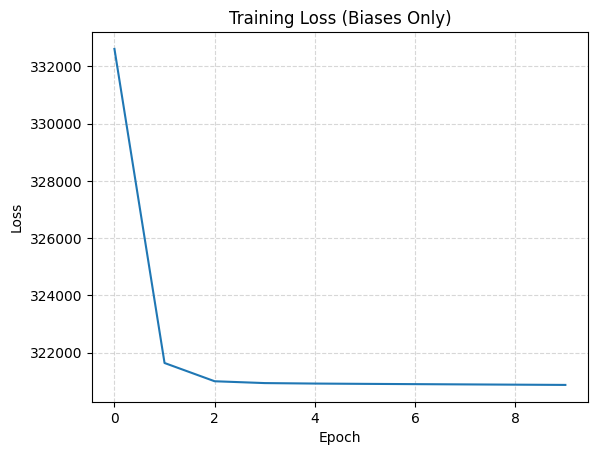

In [23]:
plt.plot(loss)
plt.title("Training Loss (Biases Only)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True, linestyle="--", alpha=0.5)

plt.savefig(f"{figures_dir}/prac2_biases_only_loss.pdf", format="pdf", bbox_inches="tight")
plt.show()

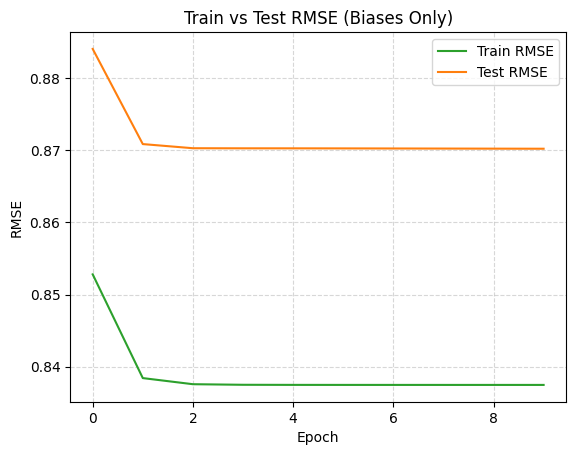

In [24]:
plt.plot(train_rmse, label="Train RMSE", color='tab:green')
plt.plot(test_rmse, label="Test RMSE", color='tab:orange')
plt.title("Train vs Test RMSE (Biases Only)")
plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()

plt.savefig(f"{figures_dir}/prac2_biases_only_rmse.pdf", format="pdf", bbox_inches="tight")
plt.show()

The tain RMSE converges to  0.8376

The test RMSE converges to 0.8677

## Practical 3: Latent Factor Model & 2D Trait Embeddings

**Task**

* Add user and item factors (latent trait vectors or matrices U and V)
* Add a sensible regularizer to your loss function
* Build a model that finds maximum likelihood estimate for user + item biases + latent trait vectors / factors with alternating least squares using data_by_user_train and data_by_movie_train
* Plot the loss function (negative log likelihood) over training iterations using data_by_user_train. It should go down monotonically!
* Plot the root mean squared error over training iterations using data_by_user_train and data_by_user_test . What does it converge to?


### Training

In [25]:
def calculate_loss(data_by_user, user_trait_vectors, movie_trait_vectors, users_biases, movies_biases, h_lambda: float, h_tau, h_gamma: float):
  """Negative Log Likelihood (Loss) - should decrease monotonically."""
  squared_error_sum = 0.0

  for user_idx, user_data in enumerate(data_by_user):
    for movie_rating in user_data:
      if not movie_rating:
        continue
      movie_idx, rating = movie_rating
      error = rating - (
          np.inner(user_trait_vectors[user_idx], movie_trait_vectors[movie_idx]) +
          users_biases[user_idx] + movies_biases[movie_idx]
          )
      squared_error_sum += error ** 2

  # L2 priors on trait_vectors
  regularizer_user_trait_vectors = sum(np.inner(user, user) for user in user_trait_vectors)
  regularizer_movie_trait_vectors = sum(np.inner(movie, movie) for movie in movie_trait_vectors)


  # L2 priors on biases
  regularizer_users_biases = sum(bias ** 2 for bias in users_biases)
  regularizer_movies_biases = sum(bias ** 2 for bias in movies_biases)

  negative_log_likelihood = (
      (0.5 * h_lambda * squared_error_sum) +
       (0.5 * h_tau * (regularizer_user_trait_vectors + regularizer_movie_trait_vectors)) +
        (0.5 * h_gamma * (regularizer_users_biases + regularizer_movies_biases))
        )
  return negative_log_likelihood


def update_trait_vectors_and_biases(data_by_user, data_by_movie, user_trait_vectors, movie_trait_vectors, users_biases, movies_biases, h_lambda: float, h_tau: float, h_gamma: float ):
  updated_users_biases = users_biases.copy()
  updated_movies_biases = movies_biases.copy()
  updated_user_trait_vectors = user_trait_vectors.copy()
  updated_movie_trait_vectors = movie_trait_vectors.copy()

  # Update user biases
  for user_idx, user_data in enumerate(data_by_user):
    error_sum = 0.0
    number_of_users = 0
    for movie_rating in user_data:
      if not movie_rating:
        continue
      movie_idx, rating = movie_rating
      error_sum += (rating -
                    np.inner(user_trait_vectors[user_idx], movie_trait_vectors[movie_idx]) -
                    movies_biases[movie_idx]
                    )
      number_of_users += 1

    updated_users_biases[user_idx] = (h_lambda * error_sum) / ((h_lambda * number_of_users) + h_gamma)


  # Update user trait vectors
  for user_idx, user_data in enumerate(data_by_user):
    n_rows = len(movie_trait_vectors[0])
    n_cols = len(movie_trait_vectors[0])

    sum_of_movie_outer_product = np.array([[0.0] * n_cols] * n_rows)
    sum_of_product_of_movie_and_error = np.array([0.0] * n_cols)

    for movie_rating in user_data:
      if not movie_rating:
        continue

      movie_idx, rating = movie_rating
      sum_of_movie_outer_product += np.outer(movie_trait_vectors[movie_idx], movie_trait_vectors[movie_idx])

      error = rating - updated_users_biases[user_idx] - movies_biases[movie_idx]
      sum_of_product_of_movie_and_error += np.array(movie_trait_vectors[movie_idx]) * error

    inverse_term = np.linalg.inv(h_lambda * sum_of_movie_outer_product +  h_tau * np.identity(len(movie_trait_vectors[movie_idx])))
    second_term = h_lambda * sum_of_product_of_movie_and_error

    updated_user_trait_vectors[user_idx] = np.matmul(inverse_term, second_term).tolist()


  # Update movie bias
  for movie_idx, movie_data in enumerate(data_by_movie):
    error_sum = 0.0
    number_of_movies = 0
    for user_rating in movie_data:
      if not user_rating:
        continue
      user_idx, rating = user_rating
      error_sum += (rating -
                    np.inner(updated_user_trait_vectors[user_idx], movie_trait_vectors[movie_idx]) -
                     updated_users_biases[user_idx]
                     )
      number_of_movies +=1

    updated_movies_biases[movie_idx] = (h_lambda * error_sum) / ((h_lambda * number_of_movies) + h_gamma)


  # Update movie trait vectors
  for movie_idx, movie_data in enumerate(data_by_movie):
    n_rows = len(updated_user_trait_vectors[0])
    n_cols = len(updated_user_trait_vectors[0])

    sum_of_user_outer_product = np.array([[0.0] * n_cols] * n_rows)
    sum_of_product_of_user_and_error = np.array([0.0] * n_cols)


    for user_rating in movie_data:
      if not user_rating:
        continue

      user_idx, rating = user_rating
      sum_of_user_outer_product += np.outer(updated_user_trait_vectors[user_idx], updated_user_trait_vectors[user_idx])

      error = rating - updated_movies_biases[movie_idx] - updated_users_biases[user_idx]
      sum_of_product_of_user_and_error += np.array(updated_user_trait_vectors[user_idx]) * error

    inverse_term = np.linalg.inv(h_lambda * sum_of_user_outer_product + h_tau * np.identity(len(updated_user_trait_vectors[user_idx])))
    second_term = h_lambda * sum_of_product_of_user_and_error

    updated_movie_trait_vectors[movie_idx] = np.matmul(inverse_term, second_term).tolist()


  return updated_user_trait_vectors, updated_movie_trait_vectors, updated_users_biases, updated_movies_biases


def calculate_root_mean_squared_error(data_by_user, user_trait_vectors, movie_trait_vectors, users_biases, movies_biases):
  squared_error_sum = 0.0
  count = 0

  for user_idx, user_data in enumerate(data_by_user):
    for movie_rating in user_data:
      if not movie_rating:
        continue
      movie_idx, rating = movie_rating
      error = rating - (
          np.inner(user_trait_vectors[user_idx], movie_trait_vectors[movie_idx]) +
          users_biases[user_idx] + movies_biases[movie_idx]
          )
      squared_error_sum += error ** 2
      count += 1

  return (squared_error_sum / count) ** 0.5 if count > 0 else 0.0


def train(data_by_user_train, data_by_movie_train, data_by_user_test,
          h_lambda: float, h_tau: float, h_gamma: float, n_epochs: int):
  # Initialize biases
  num_users = len(data_by_user_train)
  num_movies = len(data_by_movie_train)

  users_biases = np.zeros(num_users)
  movies_biases = np.zeros(num_movies)

  k=4
  rng = np.random.default_rng(42)
  user_trait_vectors = rng.standard_normal(size=(num_users, k))
  movie_trait_vectors = rng.standard_normal(size=(num_movies, k))

  train_losses = []
  train_rmses = []
  test_rmses = []

  for epoch in range(n_epochs):
    # ALS update
    user_trait_vectors, movie_trait_vectors, users_biases, movies_biases = update_trait_vectors_and_biases(
        data_by_user=data_by_user_train, data_by_movie=data_by_movie_train,
        user_trait_vectors=user_trait_vectors, movie_trait_vectors=movie_trait_vectors,
        users_biases=users_biases, movies_biases=movies_biases, h_lambda=h_lambda, h_tau=h_tau, h_gamma=h_gamma
        )

    loss = calculate_loss(
        data_by_user_train, user_trait_vectors, movie_trait_vectors, users_biases,
        movies_biases, h_lambda, h_tau, h_gamma
        )
    train_rmse = calculate_root_mean_squared_error(
        data_by_user_train, user_trait_vectors, movie_trait_vectors, users_biases,
        movies_biases
        )
    test_rmse = calculate_root_mean_squared_error(
        data_by_user_test, user_trait_vectors, movie_trait_vectors, users_biases,
        movies_biases
        )

    train_losses.append(loss)
    train_rmses.append(train_rmse)
    test_rmses.append(test_rmse)

    print(f"epoch {epoch + 1}/{n_epochs}, loss: {loss}, train rmse: {train_rmse}, test rmse: {test_rmse}")

  return users_biases, movies_biases, train_losses, train_rmses, test_rmses




In [26]:
# Hyperparameters
n_epochs = 20
h_lambda = 1
h_tau = 0.1
h_gamma = 0.1

updated_users_biases, updated_movies_biases, loss, train_rmse, test_rmse = train(
    data_by_user_train=data_by_user_train,
    data_by_movie_train=data_by_movie_train,
    data_by_user_test=data_by_user_test,
    h_lambda=h_lambda,
    h_tau=h_tau,
    h_gamma=h_gamma,
    n_epochs=n_epochs
)

epoch 1/20, loss: 325837.5492459965, train rmse: 0.8395139127845129, test rmse: 0.920844357865012
epoch 2/20, loss: 284750.1136327924, train rmse: 0.7817045935660167, test rmse: 0.8876603343355162
epoch 3/20, loss: 270331.58744219126, train rmse: 0.7608643896231366, test rmse: 0.8757925754745796
epoch 4/20, loss: 262861.4410941419, train rmse: 0.7501662595508879, test rmse: 0.8691793686759568
epoch 5/20, loss: 258502.16440266528, train rmse: 0.7439942513072457, test rmse: 0.8656030399283916
epoch 6/20, loss: 255474.50227634737, train rmse: 0.7397531161208689, test rmse: 0.8633592329253298
epoch 7/20, loss: 253103.1029460134, train rmse: 0.7364623158422485, test rmse: 0.8615228573690014
epoch 8/20, loss: 251116.93458392264, train rmse: 0.7337219999203984, test rmse: 0.8597782983238689
epoch 9/20, loss: 249438.24646277173, train rmse: 0.7314199797617351, test rmse: 0.858153183314496
epoch 10/20, loss: 248029.5011841818, train rmse: 0.7295014118448112, test rmse: 0.8567162217082337
epoch 

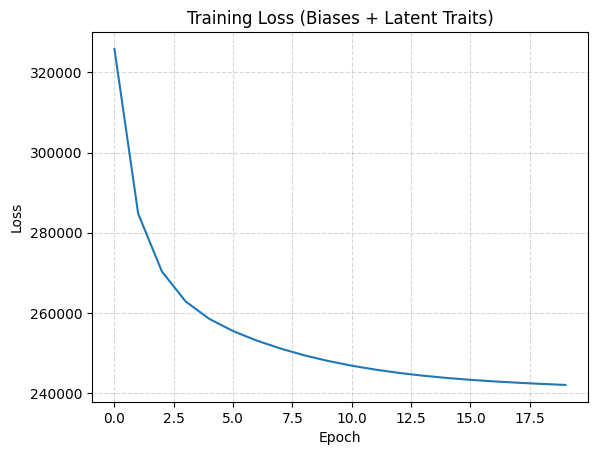

In [27]:
plt.plot(loss)
plt.title("Training Loss (Biases + Latent Traits)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True, linestyle="--", alpha=0.5)

plt.savefig(f"{figures_dir}/prac3_latent_traits_loss.pdf", format="pdf", bbox_inches="tight")
plt.show()

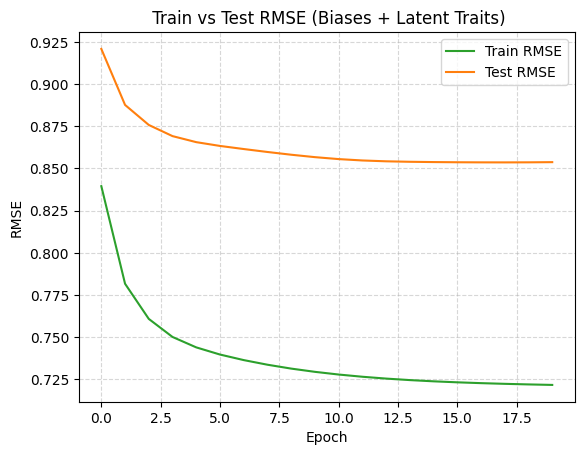

In [28]:
plt.plot(train_rmse, label="Train RMSE", color='tab:green')
plt.plot(test_rmse, label="Test RMSE", color='tab:orange')
plt.title(" Train vs Test RMSE (Biases + Latent Traits)")
plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()

plt.savefig(f"{figures_dir}/prac3_latent_traits_rmse.pdf", format="pdf", bbox_inches="tight")
plt.show()


The tain RMSE converges to 0.7221

The test RMSE converges to 0.8509

In [29]:
# cleanup of heavy array
del data
del csv_data
del user_to_index
del index_to_user
del movie_to_index
del index_to_movie
del data_by_user
del data_by_movie
del updated_users_biases, updated_movies_biases, loss, train_rmse, test_rmse

gc.collect()

13512

## Practical 4: Numba CSR, Optuna Tuning, Polarization & Dummy Users

**Task**

* Split the MovieLens 25M (or 32M) dataset into a training and a test set.
We won’t do cross-validation in this practical, but we will check whether we are overfitting on a test set! How will you create a sensible split?
* Adapt your code so that you only use the training set for optimizing parameters. Measure the RMSE on the training set and test set!
Plots the train and test RMSE on the same axis as you progress. Can you show where overfitting happens?
Is there more overfitting with K=20 latent dimensions than K=10? Or not? For which users? Is there underfitting anywhere? Do changes of λ and τ affect this?
* If you have settings of K, λ and τ that you like, train on the full dataset (next)
* Train on all 25M (or 32M) ratings. You may have to make your algorithm parallel to get this to train faster :)
* Show that if a user liked movie X (your choice) the recommendations Y make sense.
That is, create a “dummy user” that gave some movie like a “Lord of the Rings” five stars. Are the top recommendations other “Lord of the Rings” movies? You’ll need the 25M dataset for this to start looking really nice.
* Can you find and show which movies as polarizing?
Some polarizing that quickly narrows down a user’s taste once you know whether they like / dislike it. Typically movies with unusually long trait vectors v


### Load the MovieLense Dataset

In [5]:
data_path = "/content/drive/MyDrive/AIMS Courses/Block 02 - Applied Machine Learning at Scale/Practicals/dataset/ml-32m/ratings.csv"

csv_data = np.loadtxt(data_path, delimiter=',', skiprows=1, dtype=np.float32)

In [6]:
# Sort in ascecding order by timestamp
data = csv_data[csv_data[:,3].argsort()]
data[:5]

array([[3.0917000e+04, 2.1000000e+01, 3.0000000e+00, 7.8965203e+08],
       [3.0917000e+04, 1.0790000e+03, 3.0000000e+00, 7.8965203e+08],
       [2.5062000e+04, 1.1760000e+03, 4.0000000e+00, 7.8965203e+08],
       [3.0917000e+04, 4.7000000e+01, 5.0000000e+00, 7.8965203e+08],
       [3.8835000e+04, 4.8000000e+01, 4.0000000e+00, 8.2287360e+08]],
      dtype=float32)

### Build Data Structure that Indexes the data by User and by Movie

`user_to_index:dict[int, float] = {}`   # A dictionary that maps "userId" to the index of the user in the dataset

`index_to_user:list[tuple[int, float]] = []`  # A list containing the "userId" of all users, where by each userId is placed at the index set within user_to_index

`movie_to_index:dict[int, float] = {}`  # A dictionary that maps "movieId" to the index of the movie in the dataset

`index_to_movie:list[int] = []`   # A list containing the "movieId" of all movies, where by each movieId is placed at the index set within movie_to_index

`data_by_user:list[list[tuple[int, float]]] = []`   # A list where every index corresponse to a user, where each sub-list represent a tuple of movieId and ratings given by a user for a given movie.

`data_by_movie:list[list[tuple[int, float]]] = []`  # A list where every index corresponse to a movie, where each sub-list represents a tuple of userId and ratings given to the movie by the corresponding user.

In [7]:
def build_data_structure(data):
  # Six Data Structures

  user_to_index = {}        # {userId: idx}
  index_to_user = []        # [userId_1, userId_2]

  movie_to_index = {}       # {movieId: idx}
  index_to_movie = []       # A [movieId_1, movieId_2]

  data_by_user = []         # [[(movieId_1: rating_x), (movieId_2: rating_y)], [(movieId_2: rating_y), (movieId_8: rating_x)]]
  data_by_movie = []        # [[(userId_2: rating_x), (movieId_5: rating_y)], [(movieId_3: rating_y), (movieId_5: rating_x)]]


  for i in range(len(data)):  # Loop through every rating in the dataset

    # Add user entry into user_to_index and index_to_user dictionary, if it's not yet added
    if data[i][0] not in user_to_index:
      user_to_index[data[i][0]] = len(index_to_user)
      index_to_user.append(data[i][0])

    # Add movie entry into movie_to_index and index_to_movie dictionary, if it's not yet added
    if data[i][1] not in movie_to_index:
      movie_to_index[data[i][1]] = len(index_to_movie)
      index_to_movie.append(data[i][1])

    # Add movie rating to the corresponding user's index in data_by_user
    new_data_by_user_entry = (movie_to_index[data[i][1]], data[i][2])
    if len(data_by_user) < user_to_index[data[i][0]] + 1:   # Check if user's index position doesn't exists in data_by_user
      data_by_user.append([new_data_by_user_entry])
    else:
      data_by_user[user_to_index[data[i][0]]].append(new_data_by_user_entry)

    # Add user's rating to the corresponding movie's index in data_by_movie
    new_data_by_movie_entry = (user_to_index[data[i][0]], data[i][2])
    if len(data_by_movie) < movie_to_index[data[i][1]] + 1:
      data_by_movie.append([new_data_by_movie_entry])
    else:
      data_by_movie[movie_to_index[data[i][1]]].append(new_data_by_movie_entry)

  return user_to_index, index_to_user, movie_to_index, index_to_movie, data_by_user, data_by_movie


In [8]:
(user_to_index,
 index_to_user,
 movie_to_index,
 index_to_movie,
 data_by_user,
 data_by_movie) = build_data_structure(data=data)


# print("User_to_index: \n", list(user_to_index.items())[:5])
# print("\nIndex_to_user: \n", index_to_user[:5])

# print("\n\nmovies_to_index: \n", list(movie_to_index.items())[:5])
# print("\nindex_to_movie: \n", index_to_movie[:5])

# print("\n\ndata_by_user: \n", data_by_user[:2])

# print("\ndata_by_movie: \n", data_by_movie[:2])

In [9]:
# cleanup of the original heavy array
del csv_data
del data
gc.collect()

0

### Data Spliting

Split the dataset such that the most recent ratings made by a user are placed in the test dataset. The code cell below works because our dataset is sorted by timestamp in ascending order.

For users with only one rating, we store their rating in train.

In [10]:
def train_test_split(data_by_user, data_by_movie, test_size:float = 0.1):
  num_users = len(data_by_user)
  num_movies = len(data_by_movie)

  # initialise train and test sets for data by user and movie
  data_by_user_train = [[] for _ in range(num_users)]
  data_by_user_test  = [[] for _ in range(num_users)]

  data_by_movie_train = [[] for _ in range(num_movies)]
  data_by_movie_test  = [[] for _ in range(num_movies)]


  for user_idx, user_data in enumerate(data_by_user):
    n_total = len(user_data)

    # Set the number of Data points for training
    if n_total <= 1:
      n_data_points_for_train = n_total # for users with one rating, we store their rating in train.
    else:
      n_data_points_for_train = round(len(user_data) * (1 - test_size))

    counter = 0

    for movie_rating in user_data:

      movie_idx, rating = movie_rating
      user_rating = [user_idx, rating]

      # Store Data in Test
      if counter >= n_data_points_for_train:
        data_by_user_test[user_idx].append(movie_rating)
        data_by_movie_test[movie_idx].append(user_rating)

      else: # Store in Train
        data_by_user_train[user_idx].append(movie_rating)
        data_by_movie_train[movie_idx].append(user_rating)

      counter += 1

  return data_by_user_train, data_by_user_test, data_by_movie_train, data_by_movie_test


In [11]:
(data_by_user_train,
 data_by_user_test,
 data_by_movie_train,
 data_by_movie_test) = train_test_split(data_by_user, data_by_movie, test_size = 0.1)


# print("User Data: ", data_by_user[:2])
# print("User Train: ", data_by_user_train[:2])
# print("User Test: ", data_by_user_test[:2])

# print("\n--------------------------------\n")

# print("Movie Data: ", data_by_movie[:2])
# print("Movie Train: ", data_by_movie_train[:2])
# print("Movie Test: ", data_by_movie_test[:2])

In [12]:
# cleanup of the heavy array
del data_by_user
del data_by_movie
gc.collect()

0

### Training

In [13]:
def build_flat_compressed_sparse_row(data_by_object):
  offsets_per_object = [0]
  flattened_item_idxs = []
  flattened_ratings_object_oriented = []

  for item in data_by_object:
    for item_idx, rating in item:
      flattened_item_idxs.append(item_idx)
      flattened_ratings_object_oriented.append(rating)
    offsets_per_object.append(len(flattened_item_idxs))

  return (
      np.array(offsets_per_object, dtype=np.int32),
      np.array(flattened_item_idxs, dtype=np.int32),
      np.array(flattened_ratings_object_oriented, dtype=np.float64)
      )

@njit(fastmath=True)
def update_users_bias_and_trait_vector_numba(
    offsets_per_user, flattened_movie_idxs, flattened_ratings_user_oriented, user_trait_vectors,
    movie_trait_vectors, users_biases, movies_biases,
    h_lambda: float, h_tau: float, h_gamma: float ):

  updated_users_biases = users_biases.copy()
  updated_user_trait_vectors = user_trait_vectors.copy()

  k = user_trait_vectors.shape[1]
  I_k = np.eye(k)

  for m in range(len(offsets_per_user) - 1):
    start = offsets_per_user[m]
    end = offsets_per_user[m + 1]
    num_ratings = end - start

    if num_ratings == 0:
      updated_users_biases[m] = 0.0
      updated_user_trait_vectors[m, :] = 0.0
      continue

    sub_ratings = flattened_ratings_user_oriented[start:end]
    sub_movie_idxs = flattened_movie_idxs[start:end]

    # Vectorise Movie trait vector and bias
    sub_movie_trait_vectors = movie_trait_vectors[sub_movie_idxs]
    sub_movies_biases = movies_biases[sub_movie_idxs]

    # Vectorized dot product across all movies rated by the user
    residual = sub_ratings - (sub_movie_trait_vectors @ user_trait_vectors[m]) - sub_movies_biases
    new_user_bias = h_lambda * np.sum(residual) / (h_lambda * num_ratings + h_gamma)

    updated_users_biases[m] = new_user_bias

    # Matrix product on movies rated by Users
    A = h_lambda * (sub_movie_trait_vectors.T @ sub_movie_trait_vectors) + (h_tau * I_k)
    b = h_lambda * (sub_movie_trait_vectors.T @ (sub_ratings - new_user_bias - sub_movies_biases))

    updated_user_trait_vectors[m] = np.linalg.solve(A, b)

  return updated_users_biases, updated_user_trait_vectors

@njit(fastmath=True)
def update_movie_bias_and_trait_vector_numba(
    offsets_per_movie, flattened_user_idxs, flattened_ratings_movie_oriented, user_trait_vectors,
    movie_trait_vectors, users_biases, movies_biases,
    h_lambda: float, h_tau: float, h_gamma: float ):

  updated_movies_biases = movies_biases.copy()
  updated_movie_trait_vectors = movie_trait_vectors.copy()

  k = user_trait_vectors.shape[1]
  I_k = np.eye(k)

  for n in range(len(offsets_per_movie) - 1):
    start = offsets_per_movie[n]
    end = offsets_per_movie[n + 1]
    num_ratings = end - start

    if num_ratings == 0:
      updated_movies_biases[n] = 0.0
      updated_movie_trait_vectors[n, :] = 0.0
      continue

    sub_ratings = flattened_ratings_movie_oriented[start:end]
    sub_user_idxs = flattened_user_idxs[start:end]

    # Vectorise User trait vector and bias
    sub_user_trait_vectors = user_trait_vectors[sub_user_idxs]
    sub_users_biases = users_biases[sub_user_idxs]

    # Vectorized dot product across all users who rated the movie
    residual = sub_ratings - (sub_user_trait_vectors @ movie_trait_vectors[n]) - sub_users_biases
    new_movie_bias = (h_lambda * np.sum(residual)) / (h_lambda * num_ratings + h_gamma)

    updated_movies_biases[n] = new_movie_bias

    # Matrix product on users who rated the movie
    A = h_lambda * (sub_user_trait_vectors.T @ sub_user_trait_vectors) + (h_tau * I_k)
    b = h_lambda * (sub_user_trait_vectors.T @ (sub_ratings - new_movie_bias - sub_users_biases))

    updated_movie_trait_vectors[n] = np.linalg.solve(A, b)

  return updated_movies_biases, updated_movie_trait_vectors


def update_trait_vectors_and_biases(
    offsets_per_user, offsets_per_movie, flattened_user_idxs, flattened_movie_idxs, flattened_ratings_user_oriented, flattened_ratings_movie_oriented, user_trait_vectors,
    movie_trait_vectors, users_biases, movies_biases,
    h_lambda: float, h_tau: float, h_gamma: float ):

  updated_users_biases = users_biases.copy()
  updated_movies_biases = movies_biases.copy()
  updated_user_trait_vectors = user_trait_vectors.copy()
  updated_movie_trait_vectors = movie_trait_vectors.copy()

  # Update user biases and trait
  updated_users_biases, updated_user_trait_vectors = update_users_bias_and_trait_vector_numba(
    offsets_per_user=offsets_per_user,
    flattened_movie_idxs=flattened_movie_idxs,
    flattened_ratings_user_oriented=flattened_ratings_user_oriented,
    user_trait_vectors=user_trait_vectors,
    movie_trait_vectors=movie_trait_vectors,
    users_biases=users_biases,
    movies_biases=movies_biases,
    h_lambda=h_lambda,
    h_tau=h_tau,
    h_gamma=h_gamma
    )

  # Update movie bias and trait vectors
  updated_movies_biases, updated_movie_trait_vectors = update_movie_bias_and_trait_vector_numba(
    offsets_per_movie=offsets_per_movie,
    flattened_user_idxs=flattened_user_idxs,
    flattened_ratings_movie_oriented=flattened_ratings_movie_oriented,
    user_trait_vectors=updated_user_trait_vectors,
    movie_trait_vectors=movie_trait_vectors,
    users_biases=updated_users_biases,
    movies_biases=movies_biases,
    h_lambda=h_lambda,
    h_tau=h_tau,
    h_gamma=h_gamma)

  return updated_user_trait_vectors, updated_movie_trait_vectors, updated_users_biases, updated_movies_biases

@njit(fastmath=True)
def calculate_loss(offsets_per_user, flattened_movie_idxs, flattened_ratings_user_oriented, user_trait_vectors,
    movie_trait_vectors, users_biases, movies_biases,
    h_lambda: float, h_tau: float, h_gamma: float ):
  """Negative Log Likelihood (Loss) - should decrease monotonically."""
  squared_residual_sum = 0.0
  k = movie_trait_vectors.shape[1]
  I_k = np.eye(k)

  for m in range(len(offsets_per_user) - 1):
    start = offsets_per_user[m]
    end = offsets_per_user[m + 1]

    if start == end :
      continue

    sub_ratings = flattened_ratings_user_oriented[start:end]
    sub_movie_idxs = flattened_movie_idxs[start:end]

    # Vectorization
    sub_movie_trait_vectors = movie_trait_vectors[sub_movie_idxs]
    sub_movies_biases = movies_biases[sub_movie_idxs]

    residual_vector_squared = (
        sub_ratings
        - (sub_movie_trait_vectors @ user_trait_vectors[m])
        - users_biases[m]
        - sub_movies_biases
        ) ** 2

    squared_residual_sum += np.sum(residual_vector_squared)

  # L2 priors on trait_vectors
  regularizer_user_trait_vectors = np.sum(
      (user_trait_vectors.T @ user_trait_vectors) * I_k
      )
  regularizer_movie_trait_vectors = np.sum(
      (movie_trait_vectors.T @ movie_trait_vectors) * I_k
      )

  # L2 priors on biases
  regularizer_users_biases = users_biases.T @ users_biases
  regularizer_movies_biases = movies_biases.T @ movies_biases

  negative_log_likelihood = (
      (0.5 * h_lambda * squared_residual_sum) +
       (0.5 * h_tau * (regularizer_user_trait_vectors + regularizer_movie_trait_vectors)) +
        (0.5 * h_gamma * (regularizer_users_biases + regularizer_movies_biases))
        )
  return negative_log_likelihood


@njit(fastmath=True)
def calculate_root_mean_squared_error(
    offsets_per_user, flattened_movie_idxs, flattened_ratings_user_oriented, user_trait_vectors,
    movie_trait_vectors, users_biases, movies_biases,
    ):

  squared_residual_sum = 0.0
  count = 0

  for m in range(len(offsets_per_user) - 1):
    start = offsets_per_user[m]
    end = offsets_per_user[m + 1]

    if start == end:
      continue

    sub_ratings = flattened_ratings_user_oriented[start:end]
    sub_movie_idxs = flattened_movie_idxs[start:end]

    # Vectorization
    sub_movie_trait_vectors = movie_trait_vectors[sub_movie_idxs]
    sub_movies_biases = movies_biases[sub_movie_idxs]

    residual_vector_squared = (
        sub_ratings
        - (sub_movie_trait_vectors @ user_trait_vectors[m])
        - users_biases[m]
        - sub_movies_biases
        ) ** 2

    squared_residual_sum += np.sum(residual_vector_squared)
    count += len(sub_ratings)

  return (squared_residual_sum / count) ** 0.5 if count > 0 else 0.0




def train(num_users, num_movies,
          offsets_per_user_train, flattened_movie_idxs_train, flattened_ratings_user_oriented_train,
          offsets_per_movie_train, flattened_user_idxs_train, flattened_ratings_movie_oriented_train,
          offsets_per_user_test, flattened_movie_idxs_test, flattened_ratings_user_oriented_test,
          h_lambda: float, h_tau: float, h_gamma: float, h_k: int, n_epochs: int):
  # Initialize biases

  users_biases = np.zeros(num_users)
  movies_biases = np.zeros(num_movies)


  rng = np.random.default_rng(42)
  user_trait_vectors = rng.standard_normal(size=(num_users, h_k))
  movie_trait_vectors = rng.standard_normal(size=(num_movies, h_k))

  train_losses = []
  train_rmses = []
  test_rmses = []

  for epoch in range(n_epochs):
    # ALS update
    user_trait_vectors, movie_trait_vectors, users_biases, movies_biases = update_trait_vectors_and_biases(
        offsets_per_user=offsets_per_user_train,
        offsets_per_movie=offsets_per_movie_train,
        flattened_user_idxs=flattened_user_idxs_train,
        flattened_movie_idxs=flattened_movie_idxs_train,
        flattened_ratings_user_oriented=flattened_ratings_user_oriented_train,
        flattened_ratings_movie_oriented=flattened_ratings_movie_oriented_train,
        user_trait_vectors=user_trait_vectors,
        movie_trait_vectors=movie_trait_vectors,
        users_biases=users_biases,
        movies_biases=movies_biases,
        h_lambda=h_lambda,
        h_tau=h_tau,
        h_gamma=h_gamma
        )

    loss = calculate_loss(
        offsets_per_user=offsets_per_user_train,
        flattened_movie_idxs=flattened_movie_idxs_train,
        flattened_ratings_user_oriented=flattened_ratings_user_oriented_train,
        user_trait_vectors=user_trait_vectors,
        movie_trait_vectors=movie_trait_vectors,
        users_biases=users_biases,
        movies_biases=movies_biases,
        h_lambda=h_lambda,
        h_tau=h_tau,
        h_gamma=h_gamma
        )

    train_rmse = calculate_root_mean_squared_error(
        offsets_per_user=offsets_per_user_train,
        flattened_movie_idxs=flattened_movie_idxs_train,
        flattened_ratings_user_oriented=flattened_ratings_user_oriented_train,
        user_trait_vectors=user_trait_vectors,
        movie_trait_vectors=movie_trait_vectors,
        users_biases=users_biases,
        movies_biases=movies_biases,
        )
    test_rmse = calculate_root_mean_squared_error(
        offsets_per_user=offsets_per_user_test,
        flattened_movie_idxs=flattened_movie_idxs_test,
        flattened_ratings_user_oriented=flattened_ratings_user_oriented_test,
        user_trait_vectors=user_trait_vectors,
        movie_trait_vectors=movie_trait_vectors,
        users_biases=users_biases,
        movies_biases=movies_biases,
        )

    train_losses.append(loss)
    train_rmses.append(train_rmse)
    test_rmses.append(test_rmse)

    print(f"epoch {epoch + 1}/{n_epochs}, loss: {loss}, train rmse: {train_rmse}, test rmse: {test_rmse}")

  return user_trait_vectors, movie_trait_vectors, users_biases, movies_biases, train_losses, train_rmses, test_rmses


In [14]:
# Convert data into 1D compressed sparse row like arrays for Numba optimization

print("Building flatten arrays...")

(offsets_per_user_train,
 flattened_movie_idxs_train,
 flattened_ratings_user_oriented_train
 ) = build_flat_compressed_sparse_row(data_by_object=data_by_user_train)

(offsets_per_movie_train,
 flattened_user_idxs_train,
 flattened_ratings_movie_oriented_train
 ) = build_flat_compressed_sparse_row(data_by_object=data_by_movie_train)

(offsets_per_user_test,
 flattened_movie_idxs_test,
 flattened_ratings_user_oriented_test
 ) = build_flat_compressed_sparse_row(data_by_object=data_by_user_test)

num_users = len(data_by_user_train)
num_movies = len(data_by_movie_train)



Building flatten arrays...


In [15]:
# Hyperparameters
n_epochs = 20
h_lambda = 1
h_tau = 0.1
h_gamma = 0.1
h_k = 4

user_trait_vectors, movie_trait_vectors, users_biases, movies_biases, train_losses, train_rmses, test_rmses = train(
      num_users=num_users,
      num_movies=num_movies,
      offsets_per_user_train=offsets_per_user_train,
      flattened_movie_idxs_train=flattened_movie_idxs_train,
      flattened_ratings_user_oriented_train=flattened_ratings_user_oriented_train,
      offsets_per_movie_train=offsets_per_movie_train,
      flattened_user_idxs_train=flattened_user_idxs_train,
      flattened_ratings_movie_oriented_train=flattened_ratings_movie_oriented_train,
      offsets_per_user_test=offsets_per_user_test,
      flattened_movie_idxs_test=flattened_movie_idxs_test,
      flattened_ratings_user_oriented_test=flattened_ratings_user_oriented_test,
      h_lambda=h_lambda,
      h_tau=h_tau,
      h_gamma=h_gamma,
      h_k=h_k,
      n_epochs=n_epochs,
  )

epoch 1/20, loss: 10771132.025674045, train rmse: 0.8585879854551642, test rmse: 0.9094485721948893
epoch 2/20, loss: 9586268.485549109, train rmse: 0.8091315494635956, test rmse: 0.8692814630856204
epoch 3/20, loss: 9068556.070813898, train rmse: 0.7866372159433257, test rmse: 0.8513718440920486
epoch 4/20, loss: 8812714.343037877, train rmse: 0.7753223327296203, test rmse: 0.8422406060386931
epoch 5/20, loss: 8672338.437557613, train rmse: 0.7690557228875163, test rmse: 0.8368617574490235
epoch 6/20, loss: 8584504.724082239, train rmse: 0.7651178593010862, test rmse: 0.8332369607373463
epoch 7/20, loss: 8526412.225680215, train rmse: 0.7625110643936824, test rmse: 0.8307542207666605
epoch 8/20, loss: 8488574.707334636, train rmse: 0.7608164560641645, test rmse: 0.8291672798208082
epoch 9/20, loss: 8464592.72112635, train rmse: 0.7597475441362431, test rmse: 0.8281861150295596
epoch 10/20, loss: 8449356.448042579, train rmse: 0.7590736210457879, test rmse: 0.8275851855149231
epoch 11/

Average execution time without numba per epoch (Measured over 20 epochs) = 42 seconds

Average exeuction time using number per epoch (Measured over 20 epochs) = 5.5 seconds

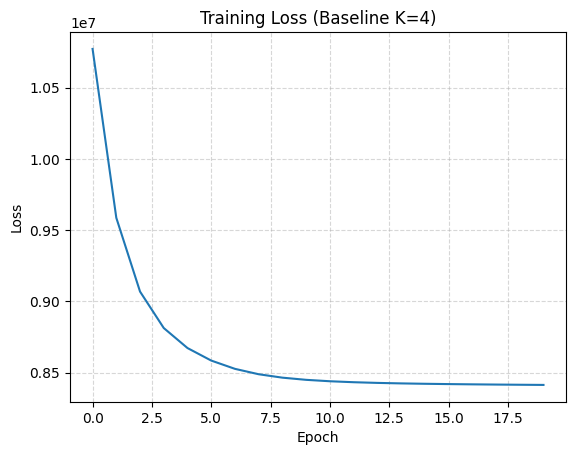

In [16]:
plt.plot(train_losses)
plt.title("Training Loss (Baseline K=4)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True, linestyle="--", alpha=0.5)

plt.savefig(f"{figures_dir}/prac4_baseline_k4_loss.pdf", format="pdf", bbox_inches="tight")
plt.show()

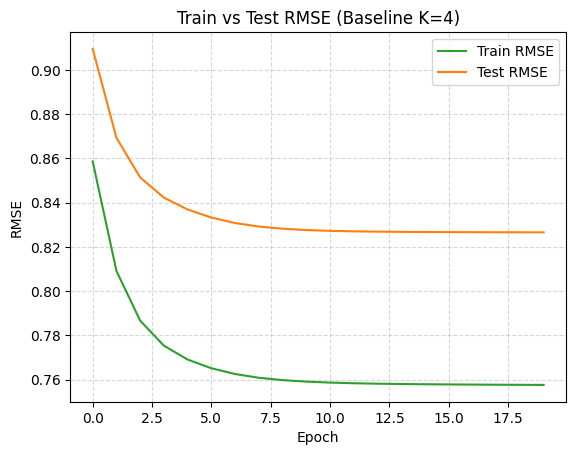

In [17]:
plt.plot(train_rmses, label="Train RMSE", color='tab:green')
plt.plot(test_rmses, label="Test RMSE", color='tab:orange')
plt.title("Train vs Test RMSE (Baseline K=4)")
plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.savefig(f"{figures_dir}/prac4_baseline_k4_rmse.pdf", format="pdf", bbox_inches="tight")
plt.show()


In [18]:
# cleanup of the heavy array
del user_trait_vectors
del movie_trait_vectors
del users_biases
del movies_biases
del train_losses
del train_rmses
del test_rmses

gc.collect()

86179

### Selecting Best Hyper parameters for training

In [19]:
def optuna_objective(trial):
  h_lambda = trial.suggest_categorical("h_lambda", [1.0])
  h_tau = trial.suggest_float(name="h_tau", low=0.01, high=10.0, log=True)
  h_gamma = trial.suggest_float(name="h_gamma", low=0.01, high=10.0, log=True)
  h_k = trial.suggest_categorical(name="h_k", choices=[2, 4, 8, 16, 32])

  n_epochs = 12

  user_trait_vectors, movie_trait_vectors, users_biases, movies_biases, train_losses, train_rmses, test_rmses = train(
      num_users=num_users,
      num_movies=num_movies,
      offsets_per_user_train=offsets_per_user_train,
      flattened_movie_idxs_train=flattened_movie_idxs_train,
      flattened_ratings_user_oriented_train=flattened_ratings_user_oriented_train,
      offsets_per_movie_train=offsets_per_movie_train,
      flattened_user_idxs_train=flattened_user_idxs_train,
      flattened_ratings_movie_oriented_train=flattened_ratings_movie_oriented_train,
      offsets_per_user_test=offsets_per_user_test,
      flattened_movie_idxs_test=flattened_movie_idxs_test,
      flattened_ratings_user_oriented_test=flattened_ratings_user_oriented_test,
      h_lambda=h_lambda,
      h_tau=h_tau,
      h_gamma=h_gamma,
      h_k=h_k,
      n_epochs=n_epochs
  )

  # Best RMSE archieved in trial
  best_rmse = min(test_rmses)

  del user_trait_vectors, movie_trait_vectors, users_biases, movies_biases, train_losses, train_rmses, test_rmses
  gc.collect()

  return best_rmse


sampler = optuna.samplers.TPESampler(seed=42)
study = optuna.create_study(direction="minimize", sampler=sampler)
study.optimize(optuna_objective, n_trials=25)


print("\n\nprint Best RMSE value: ", study.best_value)
print("\nBest Parameter: ")
for key, value in study.best_params.items():
  print(f"\t{key}: {value}")

[I 2026-10-29 14:38:23,475] A new study created in memory with name: no-name-55979bc5-92a9-4950-92a1-661eb6388ce2


epoch 1/12, loss: 18773196.53871238, train rmse: 0.8697616216161002, test rmse: 0.9098451874527861
epoch 2/12, loss: 16948264.999148674, train rmse: 0.8390336462235278, test rmse: 0.8845882082217105
epoch 3/12, loss: 15629240.785250427, train rmse: 0.8230323968402388, test rmse: 0.8715486578804136
epoch 4/12, loss: 14717559.113648834, train rmse: 0.8170208559188893, test rmse: 0.8670545877477652
epoch 5/12, loss: 14030644.340595502, train rmse: 0.8140184792698132, test rmse: 0.8641220827767292
epoch 6/12, loss: 13465411.089084864, train rmse: 0.8119855583665285, test rmse: 0.8614449877777834
epoch 7/12, loss: 12985556.52388187, train rmse: 0.8104632389461567, test rmse: 0.8590722084740322
epoch 8/12, loss: 12575472.89778711, train rmse: 0.8093233985230444, test rmse: 0.8571535071703363
epoch 9/12, loss: 12225613.910456728, train rmse: 0.808506777746724, test rmse: 0.8557105475546697
epoch 10/12, loss: 11927397.572653884, train rmse: 0.8079334251308571, test rmse: 0.8546380397063941
epo

[I 2026-10-29 14:39:12,488] Trial 0 finished with value: 0.8531712653010518 and parameters: {'h_lambda': 1.0, 'h_tau': 0.13292918943162169, 'h_gamma': 7.114476009343421, 'h_k': 2}. Best is trial 0 with value: 0.8531712653010518.


epoch 12/12, loss: 11453731.898813162, train rmse: 0.8071836037016592, test rmse: 0.8531712653010518
epoch 1/12, loss: 11611519.836071048, train rmse: 0.8578218567066158, test rmse: 0.9270322822157269
epoch 2/12, loss: 9850864.530920984, train rmse: 0.7840576408665322, test rmse: 0.8617299834238625
epoch 3/12, loss: 9210215.846579215, train rmse: 0.7551155297523617, test rmse: 0.8377624553764537
epoch 4/12, loss: 8891427.453653501, train rmse: 0.740437712658124, test rmse: 0.8253568145636939
epoch 5/12, loss: 8732129.746308904, train rmse: 0.7332486635621432, test rmse: 0.8189650715193882
epoch 6/12, loss: 8645339.543945746, train rmse: 0.7295107736641065, test rmse: 0.8154902870190326
epoch 7/12, loss: 8591717.83412994, train rmse: 0.7273373132159101, test rmse: 0.813424751898153
epoch 8/12, loss: 8555001.191699233, train rmse: 0.7259484182007235, test rmse: 0.8121111095831668
epoch 9/12, loss: 8527605.884543303, train rmse: 0.7249845574076498, test rmse: 0.8112217371050343
epoch 10/1

[I 2026-10-29 14:40:35,173] Trial 1 finished with value: 0.8097465108327615 and parameters: {'h_lambda': 1.0, 'h_tau': 3.9676050770529883, 'h_gamma': 0.6358358856676253, 'h_k': 8}. Best is trial 1 with value: 0.8097465108327615.


...

epoch 12/12, loss: 7942755.182396021, train rmse: 0.7252442054835438, test rmse: 0.8078517851444933
epoch 1/12, loss: 10891155.357468084, train rmse: 0.8608760126174195, test rmse: 0.9230096423974882
epoch 2/12, loss: 9114911.366929932, train rmse: 0.7841671334459596, test rmse: 0.8565401718001204
epoch 3/12, loss: 8540820.143907918, train rmse: 0.7561031880144354, test rmse: 0.833298807640305
epoch 4/12, loss: 8281904.965535296, train rmse: 0.7428102294011161, test rmse: 0.8218280925687659
epoch 5/12, loss: 8163603.310678084, train rmse: 0.7366046757053056, test rmse: 0.8161139496561527
epoch 6/12, loss: 8102479.435854007, train rmse: 0.7333591121272347, test rmse: 0.8129794060465272
epoch 7/12, loss: 8066496.494901695, train rmse: 0.7314239299281564, test rmse: 0.8110795964884732
epoch 8/12, loss: 8042875.401660061, train rmse: 0.730134733424211, test rmse: 0.8098356222073053
epoch 9/12, loss: 8026033.460272449, train rmse: 0.7292025579289197, test rmse: 0.808970481445697
epoch 10/12

[I 2026-10-29 15:47:07,825] Trial 23 finished with value: 0.8075167476258992 and parameters: {'h_lambda': 1.0, 'h_tau': 9.589000561092663, 'h_gamma': 0.011300907349104338, 'h_k': 8}. Best is trial 20 with value: 0.8074128660488562.


epoch 12/12, loss: 7996511.136056134, train rmse: 0.7275293975571827, test rmse: 0.8075167476258992
epoch 1/12, loss: 10890924.627093397, train rmse: 0.8608050128531508, test rmse: 0.9231388938318353
epoch 2/12, loss: 9115462.313018125, train rmse: 0.7841515088298746, test rmse: 0.8566689840756903
epoch 3/12, loss: 8539953.56668403, train rmse: 0.7560527756079357, test rmse: 0.8333945246407021
epoch 4/12, loss: 8279897.135890541, train rmse: 0.7427218724896646, test rmse: 0.821893095531867
epoch 5/12, loss: 8160934.857571397, train rmse: 0.7364925895601458, test rmse: 0.816157172247149
epoch 6/12, loss: 8099449.143158351, train rmse: 0.7332343995789249, test rmse: 0.8130090775783968
epoch 7/12, loss: 8063248.999045228, train rmse: 0.7312921152540706, test rmse: 0.8111007739339862
epoch 8/12, loss: 8039488.446539079, train rmse: 0.729998736738383, test rmse: 0.8098514382508559
epoch 9/12, loss: 8022545.459935915, train rmse: 0.7290636402631178, test rmse: 0.8089826537106782
epoch 10/12,

[I 2026-10-29 15:48:31,233] Trial 24 finished with value: 0.8075223866726823 and parameters: {'h_lambda': 1.0, 'h_tau': 9.400066058116183, 'h_gamma': 0.013654130324214045, 'h_k': 8}. Best is trial 20 with value: 0.8074128660488562.


epoch 12/12, loss: 7992802.945399825, train rmse: 0.7273833613347074, test rmse: 0.8075223866726823


print Best RMSE value:  0.8074128660488562

Best Parameter: 
	h_lambda: 1.0
	h_tau: 9.927738639118942
	h_gamma: 0.03263654625411769
	h_k: 8


In [20]:
# Training with Best Hyper parameters

best_params = study.best_params
n_epochs = 50

user_trait_vectors, movie_trait_vectors, users_biases, movies_biases, train_losses, train_rmses, test_rmses = train(
    num_users=num_users,
    num_movies=num_movies,
    offsets_per_user_train=offsets_per_user_train,
    flattened_movie_idxs_train=flattened_movie_idxs_train,
    flattened_ratings_user_oriented_train=flattened_ratings_user_oriented_train,
    offsets_per_movie_train=offsets_per_movie_train,
    flattened_user_idxs_train=flattened_user_idxs_train,
    flattened_ratings_movie_oriented_train=flattened_ratings_movie_oriented_train,
    offsets_per_user_test=offsets_per_user_test,
    flattened_movie_idxs_test=flattened_movie_idxs_test,
    flattened_ratings_user_oriented_test=flattened_ratings_user_oriented_test,
    h_lambda=best_params["h_lambda"],
    h_tau=best_params["h_tau"],
    h_gamma=best_params["h_gamma"],
    h_k=best_params["h_k"],
    n_epochs=n_epochs
)

epoch 1/50, loss: 10926863.911544938, train rmse: 0.8609537026676723, test rmse: 0.922671227818972
epoch 2/50, loss: 9148946.966500139, train rmse: 0.7841843595153625, test rmse: 0.8562360112205402
epoch 3/50, loss: 8576965.161875278, train rmse: 0.7561842510480752, test rmse: 0.8330504211163258
epoch 4/50, loss: 8319790.1218273025, train rmse: 0.7429544638193385, test rmse: 0.8216257439726576
epoch 5/50, loss: 8202509.346943403, train rmse: 0.7367888369359816, test rmse: 0.8159462834094802
epoch 6/50, loss: 8141955.513049902, train rmse: 0.7335650761923938, test rmse: 0.8128346447769319
epoch 7/50, loss: 8106326.256281292, train rmse: 0.7316425840395194, test rmse: 0.810949653782664
epoch 8/50, loss: 8082944.377197512, train rmse: 0.7303613472881202, test rmse: 0.8097150888393636
epoch 9/50, loss: 8066291.151590961, train rmse: 0.72943543919972, test rmse: 0.8088562123910656
epoch 10/50, loss: 8053878.319766989, train rmse: 0.7287361189724122, test rmse: 0.8082338789001327
epoch 11/50

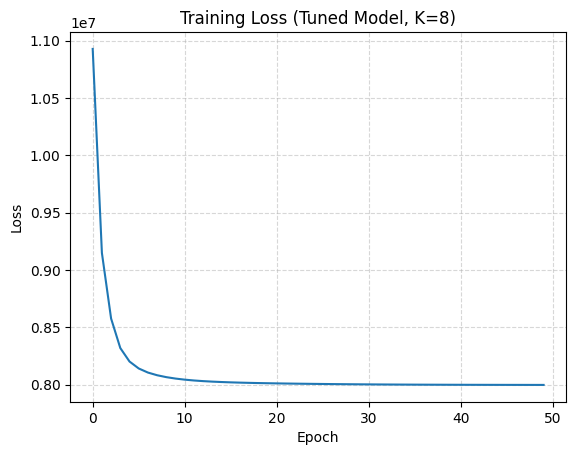

In [21]:
plt.plot(train_losses)
plt.title(f"Training Loss (Tuned Model, K={best_params['h_k']})")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True, linestyle="--", alpha=0.5)

plt.savefig(f"{figures_dir}/prac4_tuned_50epochs_loss.pdf", format="pdf", bbox_inches="tight")
plt.show()

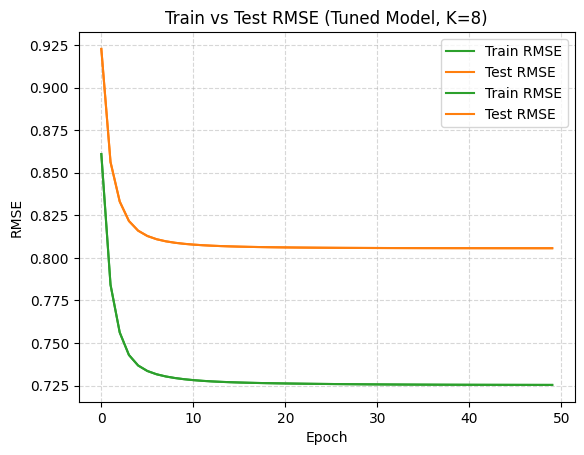

In [22]:
plt.plot(train_rmses, label="Train RMSE", color='tab:green')
plt.plot(test_rmses, label="Test RMSE", color='tab:orange')
plt.title("Train vs Test RMSE")
plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.legend()
plt.grid(True)



plt.plot(train_rmses, label="Train RMSE", color='tab:green')
plt.plot(test_rmses, label="Test RMSE", color='tab:orange')
plt.title(f"Train vs Test RMSE (Tuned Model, K={best_params['h_k']})")
plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.savefig(f"{figures_dir}/prac4_tuned_50epochs_rmse.pdf", format="pdf", bbox_inches="tight")
plt.show()

### Load Movies Dataset

In [23]:
movies_data_path = "/content/drive/MyDrive/AIMS Courses/Block 02 - Applied Machine Learning at Scale/Practicals/dataset/ml-32m/movies.csv"

movie_id_to_title = {}
movie_id_to_genres = {}

with open(movies_data_path, mode='r') as f:
  reader = csv.reader(f)
  header = next(reader) # skip header

  for row in reader:
    movie_id = int(row[0])
    movie_id_to_title[movie_id] = row[1]
    movie_id_to_genres[movie_id] = row[2]


index_to_title = {}
index_to_genres = {}

for movie_id, index in movie_to_index.items():
  movie_id_int = int(movie_id)
  index_to_title[index] = movie_id_to_title.get(movie_id_int, f"MovieId_{movie_id_int}")
  index_to_genres[index] = movie_id_to_genres.get(movie_id_int, "Unknown")


# Computing the number of ratings per movies in train
movie_support = np.array([
    offsets_per_movie_train[n + 1] - offsets_per_movie_train[n]
    for n in range(num_movies)
], dtype=np.float32)

In [24]:
print("index_to_title: ", list(index_to_title.items())[:5])
print("\nindex_to_genres: ", list(index_to_genres.items())[:5])

print("\nmovie_support: ", movie_support)

index_to_title:  [(0, 'Get Shorty (1995)'), (1, 'Fish Called Wanda, A (1988)'), (2, 'Double Life of Veronique, The (Double Vie de Véronique, La) (1991)'), (3, 'Seven (a.k.a. Se7en) (1995)'), (4, 'Pocahontas (1995)')]

index_to_genres:  [(0, 'Comedy|Crime|Thriller'), (1, 'Comedy|Crime'), (2, 'Drama|Fantasy|Romance'), (3, 'Mystery|Thriller'), (4, 'Animation|Children|Drama|Musical|Romance')]

movie_support:  [23335. 20854.  1974. ...     0.     0.     0.]


### Save Trait vectors and Biases to Drive

In [25]:
save_dir = "/content/drive/MyDrive/AIMS Courses/Block 02 - Applied Machine Learning at Scale/Practicals/saved_model"

os.makedirs(save_dir, exist_ok=True)

# Save all learned matrix factor parameters in a single compressed binary file
np.savez_compressed(
    file=f"{save_dir}/als_model_params.npz",
    user_trait_vectors=user_trait_vectors,
    movie_trait_vectors=movie_trait_vectors,
    users_biases=users_biases,
    movies_biases=movies_biases,
    movie_support=movie_support
)

# Save index mappings and meta data
mappings = {
    "user_to_index": user_to_index,
    "index_to_user": index_to_user,
    "movie_to_index": movie_to_index,
    "index_to_movie": index_to_movie,
    "index_to_title": index_to_title,
    "index_to_genres": index_to_genres,
    "best_params": best_params
}

with open(file=f"{save_dir}/model_mappings.pkl", mode="wb") as f:
  pickle.dump(mappings, f)



### Load from Disk at Inference / Runtime

In [26]:
save_dir = "/content/drive/MyDrive/AIMS Courses/Block 02 - Applied Machine Learning at Scale/Practicals/saved_model"

# Load the learned matrices and vectors from the compressed .npz file
loaded_arrays = np.load(f"{save_dir}/als_model_params.npz")

user_trait_vectors  = loaded_arrays["user_trait_vectors"]
movie_trait_vectors = loaded_arrays["movie_trait_vectors"]
users_biases        = loaded_arrays["users_biases"]
movies_biases       = loaded_arrays["movies_biases"]
movie_support       = loaded_arrays["movie_support"]

# Load the dictionary mappings and metadata from the .pkl file
with open(f"{save_dir}/model_mappings.pkl", "rb") as f:
    mappings = pickle.load(f)

user_to_index   = mappings["user_to_index"]
index_to_user   = mappings["index_to_user"]
movie_to_index  = mappings["movie_to_index"]
index_to_movie  = mappings["index_to_movie"]
index_to_title  = mappings["index_to_title"]
index_to_genres = mappings["index_to_genres"]
best_params     = mappings["best_params"]

# Helpful derived variables
num_users  = user_trait_vectors.shape[0]
num_movies = movie_trait_vectors.shape[0]
h_k        = user_trait_vectors.shape[1]

print("All parameters and mappings successfully loaded!")
print(f"Loaded {num_users} users and {num_movies} movies with latent dimension K = {h_k}.")

All parameters and mappings successfully loaded!
Loaded 200948 users and 84432 movies with latent dimension K = 8.


### Dummy Recommendation Engine

In [27]:
def find_movie_index_by_title(query: str):
  matches = []
  for idx, title in index_to_title.items():
    if query.lower() in title.lower():
      matches.append((idx, title, index_to_genres.get(idx, "Unknown"), int(movie_support[idx])))

  # Sort matches by popularity (number of ratings) descending
  matches.sort(key=lambda x: x[3], reverse=True)
  return matches


def infer_dummy_user(ratings_dict: dict, h_lambda: float, h_tau: float, h_gamma: float, k: int, n_iter: int = 5):
  dummy_bias = 0.0
  dummy_trait_vector = np.zeros(k, dtype=np.float64)
  I_k = np.eye(k, dtype=np.float64)

  movie_indices = list(ratings_dict.keys())
  ratings = np.array([ratings_dict[idx] for idx in movie_indices], dtype=np.float64)
  sub_movie_trait_vectors = movie_trait_vectors[movie_indices]
  sub_movies_biases = movies_biases[movie_indices]
  num_ratings = len(ratings)

  for _ in range(n_iter):
    # Update user bias
    residuals = ratings - ( sub_movie_trait_vectors @ dummy_trait_vector) - sub_movies_biases
    dummy_bias = (h_lambda * np.sum(residuals)) / (h_lambda * num_ratings + h_gamma)

    # Update user trait vector
    A = h_lambda * (sub_movie_trait_vectors.T @ sub_movie_trait_vectors) + (h_tau * I_k)
    b = h_lambda * (sub_movie_trait_vectors.T @ (ratings - sub_movies_biases - dummy_bias))
    dummy_trait_vector = np.linalg.solve(A, b)

  return dummy_bias, dummy_trait_vector


def recommend_for_dummy_user(ratings_dict: dict, best_params: dict, top_k: int = 10,
                             bias_dampening: float = 0.05, min_ratings: int = 100):
  # parameter extraction
  k = best_params.get("h_k", best_params.get("k", movie_trait_vectors.shape[1]))
  h_lambda = best_params.get("h_lambda", 1.0)
  h_tau = best_params.get("h_tau", 1.0)
  h_gamma = best_params.get("h_gamma", 0.1)

  dummy_bias, dummy_trait_vector = infer_dummy_user(
      ratings_dict=ratings_dict,
      h_lambda=h_lambda,
      h_tau=h_tau,
      h_gamma=h_gamma,
      k=k
      )

  # prediction score: personal trait alignment + dampened item popularity bias
  scores = (movie_trait_vectors @ dummy_trait_vector) + (bias_dampening * movies_biases)

  # exclude movies already rated by the dummy user
  for movie_idx in ratings_dict.keys():
    scores[movie_idx] = -np.inf

  # exclude obscure movies with few ratings (filters long-tail noise)
  scores[movie_support < min_ratings] = -np.inf

  top_indices = np.argsort(scores)[::-1][:top_k]

  # Print formatted recommendation table
  print(f"\n{'Rank':<5} {'Score':<8} {'Ratings':<8} {'Title':<45} {'Genres'}")
  print("-" * 95)
  for rank, idx in enumerate(top_indices, 1):
    title = index_to_title[idx][:43]
    genres = index_to_genres.get(idx, "Unknown")[:35]
    print(f"{rank:<5} {scores[idx]:<8.3f} {movie_support[idx]:<8} {title:<45} {genres}")


def analyze_polarization(movie_trait_vectors, movie_support, min_ratings: int = 500, top_k: int = 10):
  # Compute L2 norm of each movie vector: ||v_n||_2
  norms = np.sqrt(np.sum(movie_trait_vectors ** 2, axis=1))

  # Restrict to movies with substantial ratings support
  valid_indices = np.where(movie_support >= min_ratings)[0]
  valid_norms = norms[valid_indices]
  sorted_order = np.argsort(valid_norms)

  # Least Polarizing (smallest vector norms)
  least_idxs = valid_indices[sorted_order[:top_k]]
  print(f"\n--- TOP {top_k} LEAST POLARIZING MOVIES (min {min_ratings} ratings) ---")
  print(f"{'Rank':<5} {'||v||':<8} {'Ratings':<8} {'Title':<45} {'Genres'}")
  print("-" * 95)
  for rank, idx in enumerate(least_idxs, 1):
    title = index_to_title[idx][:43]
    genres = index_to_genres.get(idx, "Unknown")[:35]
    print(f"{rank:<5} {norms[idx]:<8.3f} {movie_support[idx]:<8} {title:<45} {genres}")

  # Most Polarizing (largest vector norms)
  most_idxs = valid_indices[sorted_order[::-1][:top_k]]
  print(f"\n--- TOP {top_k} MOST POLARIZING MOVIES (min {min_ratings} ratings) ---")
  print(f"{'Rank':<5} {'||v||':<8} {'Ratings':<8} {'Title':<45} {'Genres'}")
  print("-" * 95)
  for rank, idx in enumerate(most_idxs, 1):
    title = index_to_title[idx][:43]
    genres = index_to_genres.get(idx, "Unknown")[:35]
    print(f"{rank:<5} {norms[idx]:<8.3f} {movie_support[idx]:<8} {title:<45} {genres}")

In [28]:
#  Search for Lord of the Rings
matches = find_movie_index_by_title("Fellowship of the Ring")

if len(matches) > 0:
    lotr_idx, lotr_title, lotr_genres, lotr_count = matches[0]
    print(f"Dummy User rated 5.0 stars to: '{lotr_title}' (Support: {lotr_count} ratings)")

    # Get Recommendations
    recommend_for_dummy_user(
        ratings_dict={lotr_idx: 5.0},
        best_params=best_params,
        top_k=10,
        bias_dampening=0.05,
        min_ratings=100
    )
else:
    print("Movie not found! Check your search query.")

Dummy User rated 5.0 stars to: 'Lord of the Rings: The Fellowship of the Ring, The (2001)' (Support: 69612 ratings)

Rank  Score    Ratings  Title                                         Genres
-----------------------------------------------------------------------------------------------
1     0.422    64470.0  Lord of the Rings: The Return of the King,    Action|Adventure|Drama|Fantasy
2     0.414    64378.0  Lord of the Rings: The Two Towers, The (200   Adventure|Fantasy
3     0.287    81139.0  Star Wars: Episode IV - A New Hope (1977)     Action|Adventure|Sci-Fi
4     0.284    68949.0  Star Wars: Episode V - The Empire Strikes B   Action|Adventure|Sci-Fi
5     0.277    64332.0  Star Wars: Episode VI - Return of the Jedi    Action|Adventure|Sci-Fi
6     0.267    22735.0  Star Wars: Episode III - Revenge of the Sit   Action|Adventure|Sci-Fi
7     0.258    18470.0  Harry Potter and the Deathly Hallows: Part    Action|Adventure|Drama|Fantasy|Myst
8     0.256    19315.0  Harry Potter an

In [29]:
analyze_polarization(
    movie_trait_vectors=movie_trait_vectors,
    movie_support=movie_support,
    min_ratings=500,
    top_k=10)


--- TOP 10 LEAST POLARIZING MOVIES (min 500 ratings) ---
Rank  ||v||    Ratings  Title                                         Genres
-----------------------------------------------------------------------------------------------
1     0.491    643.0    Family Plot (1976)                            Comedy|Thriller
2     0.503    582.0    Purple Rain (1984)                            Drama|Musical
3     0.515    503.0    Last Night in Soho (2021)                     Drama|Horror|Mystery|Thriller
4     0.561    535.0    Tae Guk Gi: The Brotherhood of War (Taegukg   Action|Drama|War
5     0.570    529.0    Nightwatch (Nattevagten) (1994)               Horror|Thriller
6     0.573    929.0    Cobb (1994)                                   Drama
7     0.590    504.0    Leap of Faith (1992)                          Comedy|Drama
8     0.591    576.0    Enough Said (2013)                            Comedy|Drama|Romance
9     0.593    670.0    Birthday Girl (2001)                          Drama|